# M1–M4 comparison: which feature set forecasts AC load best?

Answers the research question directly: do indoor conditions (M2), outdoor weather (M3), or both (M4) improve a day-ahead forecast of zone AC load beyond calendar + AC history (M1)?

| Set | Features |
|---|---|
| M1 | calendar + AC lags |
| M2 | M1 + indoor temperature / humidity lags |
| M3 | M1 + outdoor weather |
| M4 | M1 + indoor + weather |

**Fairness rules**
1. All four sets use the **Stage 1 screened data** and feature lists from `../Feature Selection/Output/`.
2. **Same settings, two ways:**
   - **A. Fixed settings:** every set uses identical LightGBM settings, so any difference comes from the features alone.
   - **B. Tuned settings:** every set gets the same small search over settings, and keeps its best. This shows the best each set can do.
3. The tree limit is raised to 10,000 so no model is cut off before early stopping.
4. Models are **chosen on validation** (operating-hours WAPE) and **reported on test** (Jul–Sep 2018), scored on the same rows as the baselines (`scored == 1`).
5. Diebold–Mariano tests check whether M2, M3 and M4 differ significantly from M1.

The test results are cached to `outputs/m1_m4_*` so the chart and summary can be
redrawn after a kernel restart without repeating the ~10 minute retrain.

In [25]:
%pip install lightgbm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import time
import warnings
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*")
%matplotlib inline

SCREENED_DIR = Path("../Feature Selection/Output")
DATA_DIR = Path("../cleaned_data")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
CACHE_METRICS = OUT_DIR / "m1_m4_test_metrics.csv"      # lets the chart be redrawn without retraining
CACHE_CHOSEN = OUT_DIR / "m1_m4_chosen_on_validation.txt"
TARGET = "ac_load_kw"
SETS = ["M1", "M2", "M3", "M4"]
BASELINES = ["B1 seasonal naive", "B2 average profile", "B3 calendar + AC lags"]
SEED = 42

BASE_PARAMS = dict(learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                   lambda_l2=1.0, n_estimators=10_000, random_state=SEED, verbose=-1)
FIXED = {"objective": "regression_l1", "num_leaves": 63, "min_child_samples": 100}   # A. same for every set
GRID = {"objective": ["regression", "regression_l1"], "num_leaves": [31, 63], "min_child_samples": [100]}  # B.

## Load the screened data and the M1–M4 feature lists

In [27]:
df = pd.read_parquet(SCREENED_DIR / "question_b_model_data_screened.parquet")
fdict = pd.read_csv(SCREENED_DIR / "question_b_feature_dictionary_screened.csv")
baselines = pd.read_parquet(DATA_DIR / "question_b_baseline_predictions.parquet")

FEATURES = {m: fdict.loc[fdict[m].eq("Yes"), "column"].tolist() for m in SETS}
df["zone_code"] = df["zone_code"].astype("category")
train, valid, test = (df[df.split.eq(s)] for s in ["train", "validation", "test"])
full = df[df.split.isin(["train", "validation"])]
OP_VALID = valid.is_operating_hours.eq(1).values

for m in SETS:
    added = [c for c in FEATURES[m] if c not in FEATURES["M1"]]
    print(f"{m}: {len(FEATURES[m]):>2} features" + (f"  (M1 + {added})" if added else f"  {FEATURES[m]}"))

M1:  7 features  ['zone_code', 'hour', 'weekday', 'is_holiday', 'ac_load_kw_yesterday', 'ac_load_kw_2_days_ago', 'ac_load_kw_last_week']
M2: 13 features  (M1 + ['indoor_temp_c_yesterday', 'indoor_temp_c_last_week', 'indoor_temp_c_yesterday_avg', 'indoor_humidity_pct_yesterday', 'indoor_humidity_pct_last_week', 'indoor_humidity_pct_yesterday_avg'])
M3: 15 features  (M1 + ['outdoor_temp_hourly_c', 'outdoor_temp_daily_avg_c', 'outdoor_humidity_hourly_pct', 'outdoor_humidity_daily_avg_pct', 'rainfall_hourly_mm', 'rainfall_daily_total_mm', 'solar_radiation_hourly_wm2', 'solar_radiation_daily_total_mjm2'])
M4: 21 features  (M1 + ['indoor_temp_c_yesterday', 'indoor_temp_c_last_week', 'indoor_temp_c_yesterday_avg', 'indoor_humidity_pct_yesterday', 'indoor_humidity_pct_last_week', 'indoor_humidity_pct_yesterday_avg', 'outdoor_temp_hourly_c', 'outdoor_temp_daily_avg_c', 'outdoor_humidity_hourly_pct', 'outdoor_humidity_daily_avg_pct', 'rainfall_hourly_mm', 'rainfall_daily_total_mm', 'solar_radiat

## Helpers

In [28]:
def wape(y, yhat):
    y = np.asarray(y, float)
    return 100 * np.abs(y - yhat).sum() / np.abs(y).sum()


def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    err, ybar = y - yhat, y.mean()
    rmse = np.sqrt(np.mean(err ** 2))
    return {"MAE": np.mean(np.abs(err)), "RMSE": rmse, "CV(RMSE)%": 100 * rmse / ybar,
            "NMBE%": 100 * err.sum() / (len(y) * ybar), "WAPE%": wape(y, yhat)}


def fit(params, X, y, X_val=None, y_val=None, n_estimators=None):
    p = {**BASE_PARAMS, **params}
    if n_estimators:
        p["n_estimators"] = n_estimators
    model = lgb.LGBMRegressor(**p)
    kw = {"categorical_feature": ["zone_code"]}
    if X_val is not None:
        kw.update(eval_set=[(X_val, y_val)], eval_metric="l1",
                  callbacks=[lgb.early_stopping(200, verbose=False)])
    model.fit(X, y, **kw)
    return model


def predict(model, X):
    return np.clip(model.predict(X), 0, None)


def validate(m, params):
    # Fit on train with early stopping on validation; return validation scores and tree count
    feats = FEATURES[m]
    t = time.time()
    model = fit(params, train[feats], train[TARGET], valid[feats], valid[TARGET])
    pred = predict(model, valid[feats])
    return {"set": m, **params, "trees": model.best_iteration_,
            "val_WAPE_op%": wape(valid[TARGET].values[OP_VALID], pred[OP_VALID]),
            "val_WAPE_all%": wape(valid[TARGET], pred), "secs": round(time.time() - t)}


def final_predict(m, row):
    # Retrain on all of 2019 (train + validation) and predict the 2018 test period
    feats = FEATURES[m]
    params = {k: row[k] for k in ["objective", "num_leaves", "min_child_samples"]}
    n = int(row["trees"] * len(full) / len(train))           # more data -> proportionally more trees
    model = fit(params, full[feats], full[TARGET], n_estimators=n)
    return predict(model, test[feats])


def diebold_mariano(frame, a, b, max_lag=24):
    # DM on absolute error, averaged across zones per hour; Newey-West variance. DM < 0 => a better
    d = (np.abs(frame[TARGET] - frame[a]) - np.abs(frame[TARGET] - frame[b]))
    d = d.groupby(frame.timestamp).mean().sort_index().values
    n, dbar, dc = len(d), d.mean(), d - d.mean()
    lrv = dc @ dc / n + sum(2 * (1 - k / (max_lag + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, max_lag + 1))
    dm = dbar / np.sqrt(lrv / n)
    return dm, 2 * stats.norm.sf(abs(dm))

## A. Fixed settings: identical for every set

Every set uses `regression_l1`, 63 leaves, 100 minimum samples per leaf, learning rate 0.05, with early stopping on validation. Only the features differ.

In [29]:
t0 = time.time()
fixed = pd.DataFrame([validate(m, FIXED) for m in SETS])
display(fixed.round(2))
print(f"{time.time() - t0:.0f}s")

LightGBMError: scikit-learn is required for lightgbm.sklearn. You must install scikit-learn and restart your session to use this module.

## B. Tuned settings: same search for every set

Each set tries the same four combinations (L2 or L1 objective × 31 or 63 leaves) and keeps the one with the lowest validation WAPE on operating hours.

In [ ]:
t0 = time.time()
search = pd.DataFrame([validate(m, dict(zip(GRID, v))) for m in SETS for v in product(*GRID.values())])
tuned = search.sort_values("val_WAPE_op%").groupby("set").head(1).set_index("set").loc[SETS].reset_index()
display(search.sort_values(["set", "val_WAPE_op%"]).round(2))
print("Best settings per set:")
display(tuned.round(2))
print(f"{time.time() - t0:.0f}s")

,set,objective,num_leaves,min_child_samples,trees,val_WAPE_op%,val_WAPE_all%,secs
3,M1,regression_l1,63,100,5918,11.80,17.31,54
2,M1,regression_l1,31,100,1347,12.02,17.16,9
1,M1,regression,63,100,140,12.16,20.76,2
0,M1,regression,31,100,215,12.16,20.41,2
7,M2,regression_l1,63,100,5662,11.22,16.75,66
6,M2,regression_l1,31,100,4161,11.67,16.85,34
4,M2,regression,31,100,415,11.83,20.52,4
5,M2,regression,63,100,164,11.90,20.87,3
10,M3,regression_l1,31,100,5430,12.69,18.89,43
11,M3,regression_l1,63,100,3994,12.98,19.55,42


Best settings per set:


,set,objective,num_leaves,min_child_samples,trees,val_WAPE_op%,val_WAPE_all%,secs
0,M1,regression_l1,63,100,5918,11.80,17.31,54
1,M2,regression_l1,63,100,5662,11.22,16.75,66
2,M3,regression_l1,31,100,5430,12.69,18.89,43
3,M4,regression_l1,31,100,8959,12.71,19.65,87


408s


## Validation: which set would we choose?

In [ ]:
val_table = pd.DataFrame({
    "A. fixed settings": fixed.set_index("set")["val_WAPE_op%"],
    "B. tuned settings": tuned.set_index("set")["val_WAPE_op%"],
}).round(2)
val_table["vs M1 (B, pp)"] = (val_table["B. tuned settings"] - val_table.loc["M1", "B. tuned settings"]).round(2)
display(val_table)
chosen = val_table["B. tuned settings"].idxmin()
CACHE_CHOSEN.write_text(chosen)
print(f"Chosen on validation (tuned settings): {chosen}")

,A. fixed settings,B. tuned settings,"vs M1 (B, pp)"
set,,,
M1,11.80,11.80,0.00
M2,11.22,11.22,-0.58
M3,12.98,12.69,0.89
M4,12.83,12.71,0.91


Chosen on validation (tuned settings): M2


## Test: retrain on all of 2019 and score Jul–Sep 2018

Both versions (A and B) of every set are retrained on train + validation and scored on the test rows used for the baselines.

In [ ]:
t0 = time.time()
test_pred = test[["zone_id", "timestamp"]].copy()
for label, table in [("A", fixed), ("B", tuned)]:
    for _, row in table.iterrows():
        test_pred[f"{row['set']} ({label})"] = final_predict(row["set"], row)
MODEL_COLS = [c for c in test_pred.columns if c.startswith("M")]

cmp = baselines[baselines.period.eq("test")].merge(test_pred, on=["zone_id", "timestamp"], how="left")
cmp = cmp[cmp.scored.eq(1)].copy()
assert cmp[BASELINES + MODEL_COLS].notna().all().all(), "missing predictions on scored rows"
op = cmp[cmp.is_operating_hours.eq(1)]

results = pd.DataFrame([{"model": c, "hours": h, **metrics(f[TARGET], f[c])}
                        for h, f in [("operating hours", op), ("all hours", cmp)]
                        for c in BASELINES + MODEL_COLS])
results.to_csv(CACHE_METRICS, index=False)
display(results.pivot(index="model", columns="hours", values="WAPE%").round(2)
        .sort_values("operating hours"))
display(results[results.hours.eq("operating hours")].set_index("model").drop(columns="hours").round(2))
print(f"{time.time() - t0:.0f}s")

hours,all hours,operating hours
model,,
M1 (A),16.77,10.45
M1 (B),16.77,10.45
M3 (B),18.38,11.61
M3 (A),18.98,12.03
M4 (A),19.73,12.21
M4 (B),19.53,12.43
M2 (B),19.53,12.75
M2 (A),19.53,12.75
B1 seasonal naive,28.33,16.92


,MAE,RMSE,CV(RMSE)%,NMBE%,WAPE%
model,,,,,
B1 seasonal naive,2.31,4.77,34.87,4.70,16.92
B2 average profile,2.66,3.85,28.13,-11.83,19.47
B3 calendar + AC lags,2.48,4.02,29.41,4.07,18.12
M1 (A),1.43,2.53,18.51,-2.52,10.45
M2 (A),1.74,2.91,21.25,-6.44,12.75
M3 (A),1.65,2.73,19.93,3.80,12.03
M4 (A),1.67,2.81,20.53,0.85,12.21
M1 (B),1.43,2.53,18.51,-2.52,10.45
M2 (B),1.74,2.91,21.25,-6.44,12.75


562s


## Is the difference from M1 significant? (Diebold–Mariano)

In [ ]:
dm_rows = []
for label in ["A", "B"]:
    for m in ["M2", "M3", "M4"]:
        for h, f in [("operating hours", op), ("all hours", cmp)]:
            dm, p = diebold_mariano(f, f"{m} ({label})", f"M1 ({label})")
            dm_rows.append({"settings": label, "model": m, "vs": "M1", "hours": h, "DM": dm, "p_value": p,
                            "result": ("better than M1" if dm < 0 else "worse than M1") if p < 0.05 else "no significant difference"})
display(pd.DataFrame(dm_rows).round(3))

,settings,model,vs,hours,DM,p_value,result
0,A,M2,M1,operating hours,7.640,0.000,worse than M1
1,A,M2,M1,all hours,8.672,0.000,worse than M1
2,A,M3,M1,operating hours,3.035,0.002,worse than M1
3,A,M3,M1,all hours,4.481,0.000,worse than M1
4,A,M4,M1,operating hours,3.715,0.000,worse than M1
5,A,M4,M1,all hours,5.130,0.000,worse than M1
6,B,M2,M1,operating hours,7.640,0.000,worse than M1
7,B,M2,M1,all hours,8.672,0.000,worse than M1
8,B,M3,M1,operating hours,2.831,0.005,worse than M1
9,B,M3,M1,all hours,4.093,0.000,worse than M1


## Chart

In [ ]:
# Resume point. The chart and summary below need only `results` and `chosen`.
# After a kernel restart, reload them from the cache rather than repeating the
# retrain in the cell above, which takes about 10 minutes.
if "results" not in globals():
    results = pd.read_csv(CACHE_METRICS)
    chosen = CACHE_CHOSEN.read_text().strip()
    print(f"Reloaded cached test metrics from {CACHE_METRICS} | chosen on validation: {chosen}")


Reloaded cached test metrics from outputs\m1_m4_test_metrics.csv | chosen on validation: M2


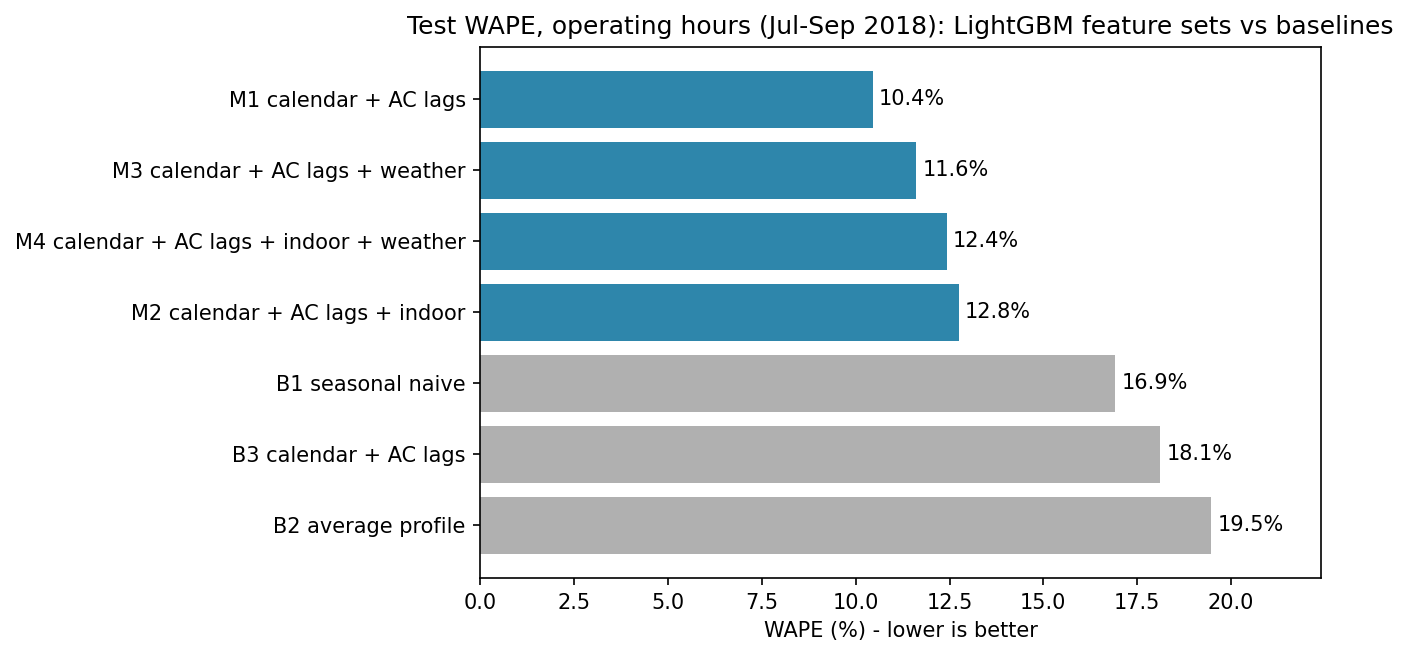

In [ ]:
LABELS = {
    "M1 (B)": "M1 calendar + AC lags",
    "M2 (B)": "M2 calendar + AC lags + indoor",
    "M3 (B)": "M3 calendar + AC lags + weather",
    "M4 (B)": "M4 calendar + AC lags + indoor + weather",
}
op_res = results[results.hours.eq("operating hours")].set_index("model")["WAPE%"]
r = op_res[list(LABELS) + BASELINES].rename(index=LABELS).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(r.index, r.values, color=["#2E86AB" if i.startswith("M") else "#B0B0B0" for i in r.index])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(xlabel="WAPE (%) - lower is better",
       title="Test WAPE, operating hours (Jul-Sep 2018): LightGBM feature sets vs baselines")
ax.set_xlim(0, r.max() * 1.15)
plt.tight_layout()
plt.show()

## Summary of results

In [ ]:
best_test = results[results.hours.eq("operating hours") & results.model.isin(LABELS)].copy()
best_test["model"] = best_test.model.map(LABELS)
print("Test, operating hours, tuned settings:")
print(best_test.sort_values("WAPE%")[["model", "WAPE%", "CV(RMSE)%", "NMBE%"]].round(2).to_string(index=False))
print(f"\nChosen on validation: {chosen}  |  Best on test: {best_test.sort_values('WAPE%').iloc[0].model}")

Test, operating hours, tuned settings:
                                   model  WAPE%  CV(RMSE)%  NMBE%
                   M1 calendar + AC lags  10.45      18.51  -2.52
         M3 calendar + AC lags + weather  11.61      19.62   3.21
M4 calendar + AC lags + indoor + weather  12.43      20.34  -0.51
          M2 calendar + AC lags + indoor  12.75      21.25  -6.44

Chosen on validation: M2  |  Best on test: M1 calendar + AC lags


## Conclusion

### Answer to the question
**Yes, a zone's AC energy demand can be forecast accurately one day ahead, but indoor conditions and weather are not what make it accurate.**
- The best model uses only the **calendar and the zone's own AC history** (M1). It is off by about **10.4% of the AC energy** in working hours (about 1.4 kW per zone per hour on average). It meets the ASHRAE Guideline 14 accuracy limits comfortably (CV(RMSE) 18.5% against a 30% limit, NMBE −2.5% against ±10%).
- That is **about 6.5 percentage points more accurate than the best simple rule** ("same as last week", 16.9%).
- Adding indoor temperature and humidity, outdoor weather, or both **did not improve** the forecast. On the 2018 test period all three versions were slightly but significantly less accurate (11.6–12.8%).

### What this means for the building
1. **Deploy the simple forecast.** A forecast built from the BMS's own AC meter history and the calendar is accurate enough for day-ahead planning. It needs **no paid weather-forecast feed and no extra indoor-sensor integration**, which keeps it cheap and robust.
2. **Use it to plan, not just to predict.**
   - **Pre-cooling and start-up:** where several zones on a floor are forecast to peak at the same hour, stagger their start times to cut the building's peak demand.
   - **Daily energy budget:** sum the zone forecasts into a next-day AC energy estimate for operations and ESG reporting.
3. **Use it as a fault and waste detector.** When a zone's actual AC load is well above its forecast, for example on a weekend, at night or during the lunch shutdown, flag it for **inspection**. Treat it as a lead, not proof of a fault.
4. **Protect the data the forecast depends on.** Accuracy rests on clean AC meter history. Gaps or faulty meters (such as the dead unit in F2 zone 2) directly degrade the forecast, so meter maintenance and data-quality checks matter more than adding new sensors.
5. **Keep the holiday calendar up to date.** Forecasts are weakest around public holidays, when "last week" or "yesterday" was not a normal working day. Keeping the holiday list current, and checking forecasts manually around long weekends, avoids the biggest errors.

### What it does **not** mean
- **Indoor sensors are still worth keeping.** They matter for comfort monitoring and fault diagnosis. They just don't improve a *day-ahead* AC energy forecast. On the 2019 data, where sensors were more complete, indoor features helped slightly, so with **better sensor uptime** they may yet add value.
- **Weather is not irrelevant to AC load.** Its effect is already captured in yesterday's and last week's load, because Bangkok's weather changes little from day to day. Weather may matter more for **unusual days** (sudden heat or storms) or **shorter horizons** (an hour ahead), which this study did not test.

### Limitations
- Tested on one out-of-year period (Jul–Sep 2018, the rainy season) with more indoor-sensor gaps than the training year.
- Observed weather was used in place of real forecasts. Real forecasts carry error, which would make weather even less useful.
- No occupancy data, so the forecast cannot react to unusual occupancy (events, closures) unless they show up in the calendar.

### Recommended next steps
1. Adopt the **M1 forecast** as the operational day-ahead model, and re-train it monthly as new meter data arrives.
2. Track forecast accuracy (WAPE and CV(RMSE)) per zone each month, and investigate zones whose error grows.
3. Re-test indoor and weather features once sensor uptime improves, and for an hour-ahead forecast, where they are more likely to help.